
# Category Intelligence - Retail Product Performance EDA

# **Name:** Bade Rani  
# **Course:** Calibo AI Academy  
# **Batch:** DIET  
# **Module:** Python Libraries - Matplotlib & Seaborn (EDA)  
# **Industry:** Retail / E-commerce  
# **Dataset:** MUC01_Retail_Sales_Dataset.csv

## Introduction

The purpose of this analysis is to understand retail product performance using six months of sales data from January to June 2026.

This analysis examines category revenue trends, top and bottom products, discount effectiveness, and sales patterns. The findings will help the Category Manager make data-driven decisions about product categories, suppliers, and promotions.



# CBIM Problem Canvas

## 1. Situation (S)
A regional retail chain operates 12 stores across Andhra Pradesh and sells products across five categories. The Category Manager is preparing for a quarterly supplier review meeting.

## 2. Complication (C)
The Category Manager needs clear evidence about which categories and products are performing well and which are underperforming. She also needs to understand whether discounts are generating additional revenue.

## 3. Question (Q)
Which product categories are growing or declining, which products are driving performance, and what actions should the Category Manager take before the supplier review?

## 4. SSOT (Single Source of Truth)
The file MUC01_Retail_Sales_Dataset.csv is the single source of truth for this analysis.

## 5. Success Definition
The analysis should identify category revenue trends, top and bottom products, discount effectiveness, and sales patterns. It should provide clear, data-backed recommendations for the supplier review.

## 6. Primary Stakeholder
The primary stakeholder is the Category Manager, who needs evidence to make decisions about supplier performance, shelf space, investment, and promotions.



# Step 1: Load and Inspect the Data

## Objective
To load the retail sales dataset and understand its structure, data types, missing values, and numerical summaries.

## Business Purpose
Understanding the dataset is the first step before analysing sales performance. It helps identify the available information and any data quality issues.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("MUC01_Retail_Sales_Dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())
df.info()
display(df.isnull().sum())
display(df.describe())

print("Unique products:", df["product_name"].nunique())
print("Unique categories:", df["category"].nunique())

Dataset shape: (107836, 10)


,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
0,TXN000001,2026-01-01,S01,Vijayawada,Electronics,Smart TV,2,3075.46,5843.37,5
1,TXN000002,2026-01-01,S01,Vijayawada,Electronics,Laptop,1,11598.06,11598.06,0
2,TXN000003,2026-01-01,S01,Vijayawada,Electronics,Tablet,3,5738.37,15493.60,10
3,TXN000004,2026-01-01,S01,Vijayawada,Electronics,Smart TV,3,3281.28,9351.65,5
4,TXN000005,2026-01-01,S01,Vijayawada,Apparel,Jeans,1,1917.14,1917.14,0


<class 'pandas.DataFrame'>
RangeIndex: 107836 entries, 0 to 107835
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   transaction_id  107836 non-null  str    
 1   date            107836 non-null  str    
 2   store_id        107836 non-null  str    
 3   store_city      107836 non-null  str    
 4   category        107836 non-null  str    
 5   product_name    107836 non-null  str    
 6   units_sold      107836 non-null  int64  
 7   unit_price      107836 non-null  float64
 8   revenue         107836 non-null  float64
 9   discount_pct    107836 non-null  int64  
dtypes: float64(2), int64(2), str(6)
memory usage: 8.2 MB


transaction_id    0
date              0
store_id          0
store_city        0
category          0
product_name      0
units_sold        0
unit_price        0
revenue           0
discount_pct      0
dtype: int64

,units_sold,unit_price,revenue,discount_pct
count,107836.000000,107836.000000,107836.000000,107836.000000
mean,2.583488,1778.097787,4263.920924,7.228152
std,1.471616,5053.631792,14243.244169,6.730445
min,1.000000,50.020000,40.040000,0.000000
25%,1.000000,274.827500,467.772500,0.000000
50%,2.000000,488.450000,1034.615000,5.000000
75%,3.000000,1039.522500,2473.335000,10.000000
max,13.000000,44990.140000,355090.880000,20.000000


Unique products: 25
Unique categories: 5



# Step 2: Category Revenue Trend Over Time

## Objective
To analyse monthly revenue for all five product categories from January to June 2026.

## Business Purpose
Monthly revenue trends help identify growing, declining, and consistent categories. This information helps the Category Manager decide where to focus investment and supplier discussions.


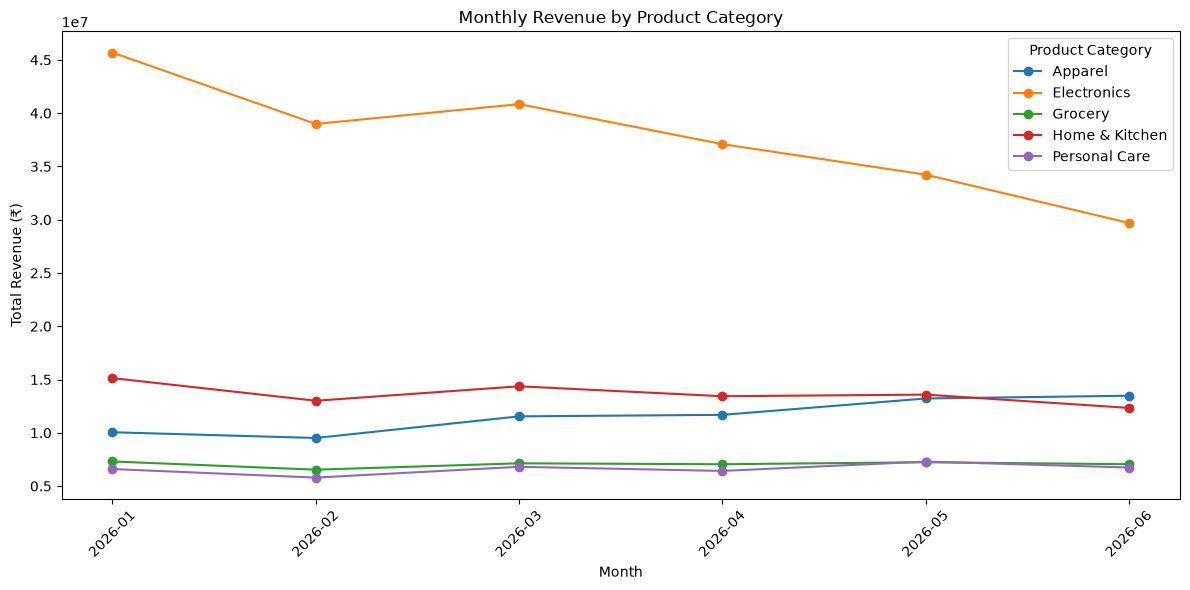

category,Apparel,Electronics,Grocery,Home & Kitchen,Personal Care
month,,,,,
2026-01,10049916.78,45686596.63,7307011.34,15130871.54,6593734.81
2026-02,9510938.10,38988602.50,6534957.35,13006413.31,5792754.97
2026-03,11540439.47,40846509.47,7132787.06,14362119.50,6808029.34
2026-04,11681806.66,37092265.09,7047399.58,13431147.66,6417868.13
2026-05,13219535.79,34226926.43,7232706.20,13581886.25,7298818.71
2026-06,13476952.88,29686824.81,7047719.23,12333283.07,6737354.12


In [16]:

df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.to_period("M").astype(str)

monthly_revenue = df.pivot_table(
    index="month",
    columns="category",
    values="revenue",
    aggfunc="sum"
)

monthly_revenue.plot(marker="o", figsize=(12, 6))
plt.title("Monthly Revenue by Product Category")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=45)
plt.legend(title="Product Category")
plt.tight_layout()
plt.show()

display(monthly_revenue)


In [17]:
print(monthly_revenue)

category      Apparel  Electronics     Grocery  Home & Kitchen  Personal Care
month                                                                        
2026-01   10049916.78  45686596.63  7307011.34     15130871.54     6593734.81
2026-02    9510938.10  38988602.50  6534957.35     13006413.31     5792754.97
2026-03   11540439.47  40846509.47  7132787.06     14362119.50     6808029.34
2026-04   11681806.66  37092265.09  7047399.58     13431147.66     6417868.13
2026-05   13219535.79  34226926.43  7232706.20     13581886.25     7298818.71
2026-06   13476952.88  29686824.81  7047719.23     12333283.07     6737354.12


### Business Interpretation

The monthly revenue trends show how each product category performs over the six-month period.

- The category with the steepest decline is **Electronics**, with revenue decreasing by approximately 35.02% from January to June 2026.
- The most consistent category is **Grocery**, with relatively stable monthly revenue throughout the period.
- The Category Manager should investigate the reasons for declining Electronics revenue and review supplier performance before making decisions about shelf space and promotional investment.


# Step 3: Top and Bottom Products by Category

In this step, I calculate total revenue for each product over the six-month period. I identify the top two and bottom two products in every category to understand which products contribute most and least to revenue.


In [18]:

product_revenue = (
    df.groupby(["category", "product_name"])["revenue"]
    .sum()
    .reset_index()
)

product_revenue = product_revenue.sort_values(
    ["category", "revenue"],
    ascending=[True, False]
)

for category in sorted(product_revenue["category"].unique()):
    category_products = product_revenue[
        product_revenue["category"] == category
    ]

    print("\nCategory:", category)
    display(pd.concat([
        category_products.head(2).assign(
            Performance="Top 2"
        ),
        category_products.tail(2).assign(
            Performance="Bottom 2"
        )
    ]))



Category: Apparel


,category,product_name,revenue,Performance
3,Apparel,Saree,14161864.63,Top 2
4,Apparel,T-Shirt,14099251.65,Top 2
0,Apparel,Formal Shirt,13748976.91,Bottom 2
2,Apparel,Kurta,13606747.03,Bottom 2



Category: Electronics


,category,product_name,revenue,Performance
5,Electronics,Headphones,47696053.99,Top 2
6,Electronics,Laptop,46551078.39,Top 2
9,Electronics,Tablet,44744388.93,Bottom 2
8,Electronics,Smart TV,41882166.21,Bottom 2



Category: Grocery


,category,product_name,revenue,Performance
13,Grocery,Rice (5kg),8562171.86,Top 2
11,Grocery,Dal (1kg),8488303.64,Top 2
12,Grocery,Oil (1L),8431630.01,Bottom 2
14,Grocery,Sugar (1kg),8377786.05,Bottom 2



Category: Home & Kitchen


,category,product_name,revenue,Performance
16,Home & Kitchen,Mixer Grinder,16903254.58,Top 2
18,Home & Kitchen,Storage Box,16676535.31,Top 2
17,Home & Kitchen,Pressure Cooker,16142329.39,Bottom 2
19,Home & Kitchen,Water Bottle,15825842.17,Bottom 2



Category: Personal Care


,category,product_name,revenue,Performance
22,Personal Care,Shampoo,8168328.26,Top 2
20,Personal Care,Body Lotion,8106578.00,Top 2
24,Personal Care,Toothpaste,7768812.48,Bottom 2
23,Personal Care,Sunscreen,7593863.45,Bottom 2


### Business Interpretation

- In Apparel, Saree and T-Shirt are the top-performing products, while Kurta and Formal Shirt are among the bottom performers.
- In Electronics, Headphones and Laptop generate the highest revenue, while Smart TV and Tablet are among the bottom performers.
- The Category Manager should review the lower-performing products with suppliers and investigate pricing, demand, and stock availability before deciding on shelf space.


# Step 4: Discount Effectiveness Analysis

In this step, I group transactions into discount brackets: 0%, 5%, 10%, 15%, 20%, and 25% or above.

I compare average revenue per transaction and average units sold to understand the relationship between discounts and sales performance.


,Average_Revenue,Average_Units_Sold,Transaction_Count
discount_bracket,,,
0%,4685.654340,2.586018,36033.0
5%,4303.730312,2.591882,23922.0
10%,4005.545405,2.566401,23810.0
15%,4069.164408,2.595140,11935.0
20%,3631.727433,2.581493,12136.0
25%+,NaN,NaN,NaN


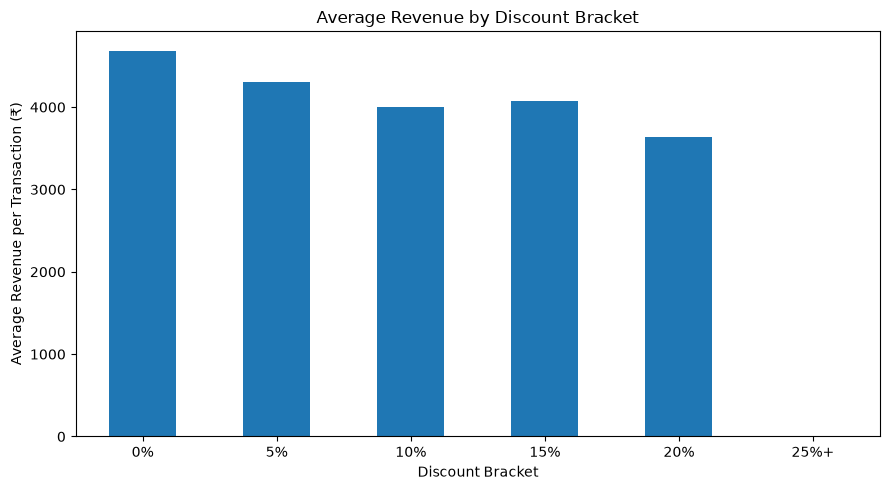

In [19]:

df["discount_bracket"] = np.select(
    [
        df["discount_pct"] == 0,
        df["discount_pct"] == 5,
        df["discount_pct"] == 10,
        df["discount_pct"] == 15,
        df["discount_pct"] == 20,
        df["discount_pct"] >= 25
    ],
    ["0%", "5%", "10%", "15%", "20%", "25%+"],
    default="Other"
)

discount_order = ["0%", "5%", "10%", "15%", "20%", "25%+"]

discount_analysis = (
    df[df["discount_bracket"] != "Other"]
    .groupby("discount_bracket")
    .agg(
        Average_Revenue=("revenue", "mean"),
        Average_Units_Sold=("units_sold", "mean"),
        Transaction_Count=("transaction_id", "count")
    )
    .reindex(discount_order)
)

display(discount_analysis)

discount_analysis["Average_Revenue"].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Average Revenue by Discount Bracket")
plt.xlabel("Discount Bracket")
plt.ylabel("Average Revenue per Transaction (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Business Interpretation

- Average revenue per transaction decreases overall as discounts increase, from ₹4,685.65 at 0% discount to ₹3,631.73 at 20% discount.
- Average units sold remain almost the same across all discount levels.
- Higher discounts do not show a clear increase in units sold in this dataset.
- The 25%+ discount bracket has no data because the maximum discount recorded is 20%.
- The business should review its discount strategy. Profit impact cannot be confirmed because cost and profit data are unavailable.


# Step 5: Day-of-Week and Monthly Sales Patterns

In this step, I analyse sales by day of the week and by month. I identify the best and worst days and months for the retail chain. I also examine the sales pattern of the category with the steepest decline to support promotional planning.


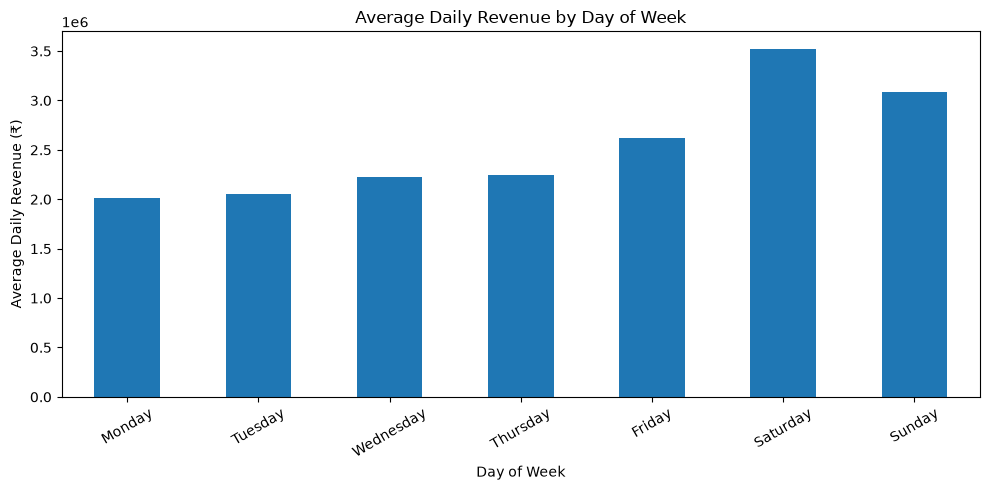

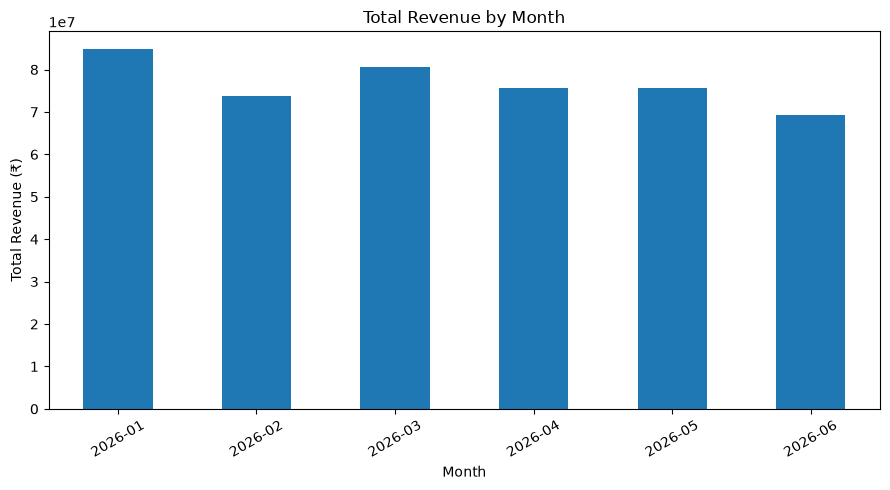

Best weekday: Saturday
Worst weekday: Monday
Best month: 2026-01
Worst month: 2026-06
Category to investigate: Electronics
Revenue change (%): -35.02


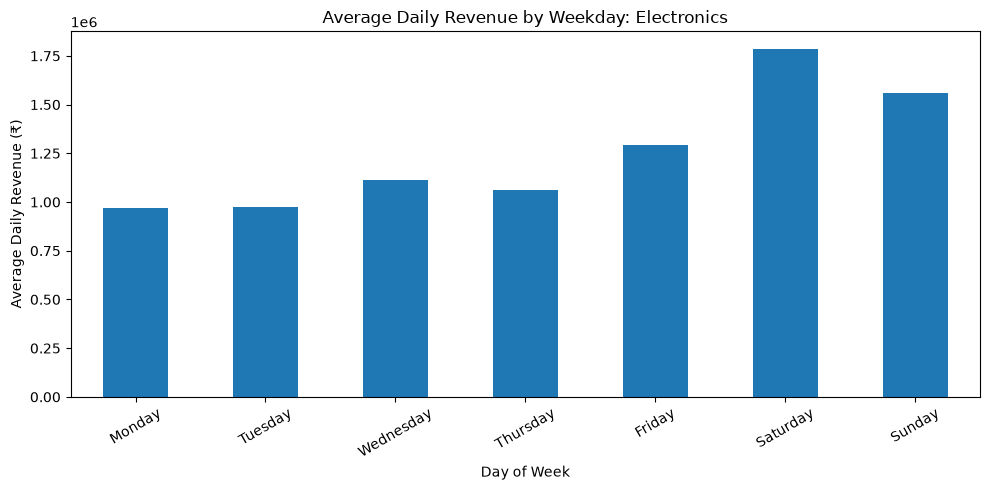

Best day for selected category: Saturday
Worst day for selected category: Monday


In [20]:

df["day_name"] = df["date"].dt.day_name()

# Total revenue for each date
daily_revenue = df.groupby("date")["revenue"].sum()

# Average daily revenue for each weekday
weekday_revenue = daily_revenue.groupby(
    daily_revenue.index.day_name()
).mean()

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
weekday_revenue = weekday_revenue.reindex(weekday_order)

weekday_revenue.plot(kind="bar", figsize=(10, 5))
plt.title("Average Daily Revenue by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Revenue (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Total revenue by month
total_monthly_revenue = df.groupby("month")["revenue"].sum()

total_monthly_revenue.plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Total Revenue by Month")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Best weekday:", weekday_revenue.idxmax())
print("Worst weekday:", weekday_revenue.idxmin())
print("Best month:", total_monthly_revenue.idxmax())
print("Worst month:", total_monthly_revenue.idxmin())

# Find the category with the largest percentage decline
first_month = monthly_revenue.iloc[0]
last_month = monthly_revenue.iloc[-1]

decline_pct = (
    (last_month - first_month) / first_month.replace(0, np.nan)
) * 100

category_focus = decline_pct.idxmin()

print("Category to investigate:", category_focus)
print("Revenue change (%):", round(decline_pct[category_focus], 2))

# Weekday pattern for the selected category
focus_df = df[df["category"] == category_focus]
focus_daily = focus_df.groupby("date")["revenue"].sum()

focus_weekday = focus_daily.groupby(
    focus_daily.index.day_name()
).mean().reindex(weekday_order)

focus_weekday.plot(kind="bar", figsize=(10, 5))
plt.title(f"Average Daily Revenue by Weekday: {category_focus}")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Revenue (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Best day for selected category:", focus_weekday.idxmax())
print("Worst day for selected category:", focus_weekday.idxmin())


### Business Interpretation

- Saturday is the best-performing weekday, while Monday is the worst-performing weekday.
- January 2026 is the best-performing month, while June 2026 is the worst-performing month.
- Electronics needs further investigation because its revenue decreased by 35.02% from January to June 2026.
- For Electronics, Saturday performs best and Monday performs worst.
- The business should review Monday sales, investigate the decline in Electronics revenue, and plan suitable promotions or stock adjustments based on further analysis.

## Step 6.6: Category Manager Briefing

Electronics needs immediate review because its revenue declined by 35.02%, from ₹45,686,596.63 in January to ₹29,686,824.81 in June 2026. Apparel has the strongest case for increased investment because its revenue grew from ₹10,049,916.78 in January to ₹13,476,952.88 in June. I would challenge the Electronics category, especially Smart TV, which generated ₹41,882,166.21 in revenue, and investigate its performance. Average revenue per transaction fell from ₹4,685.65 at 0% discount to ₹3,631.73 at 20% discount, while average units sold stayed almost unchanged. I recommend reviewing discount effectiveness and investigating Monday sales, the lowest-performing weekday. Before making a final investment decision, I would request product-level profit margins and stock availability data.